(50, 4)
[0.031 0.012 0.039 0.039]
Mercado: 541
Tamanho: 490
Valor: 4,145
Momentum: 836
Completa: 9,729


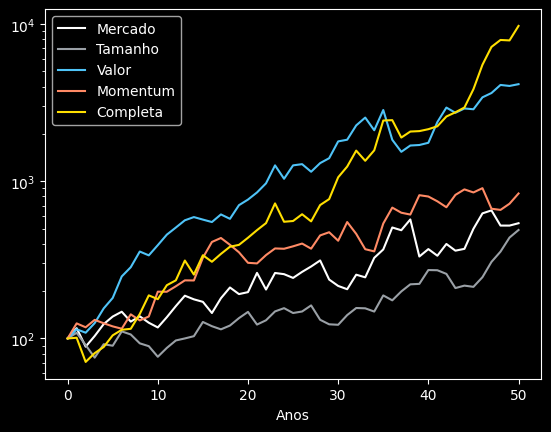

Mercado: E(R) = 8.0%  vol = 18.9%  riqueza = 4,690
Tamanho: E(R) = 5.0%  vol = 14.1%  riqueza = 1,147
Valor: E(R) = 6.0%  vol = 14.1%  riqueza = 1,842
Momentum: E(R) = 7.0%  vol = 15.6%  riqueza = 2,946
Completa: E(R) = 12.5%  vol = 21.0%  riqueza = 36,110


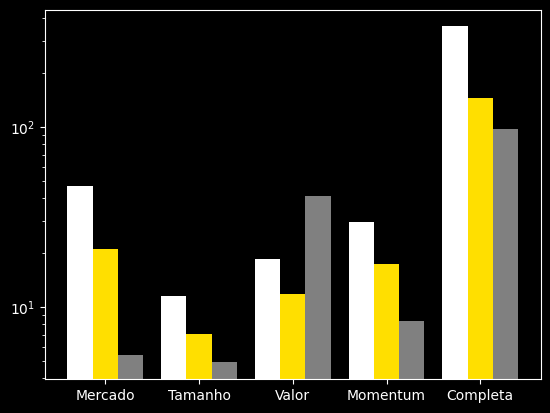

[0.004 0.809 0.505 0.563 0.592]
[0.016 0.103 0.165 0.143 0.133]


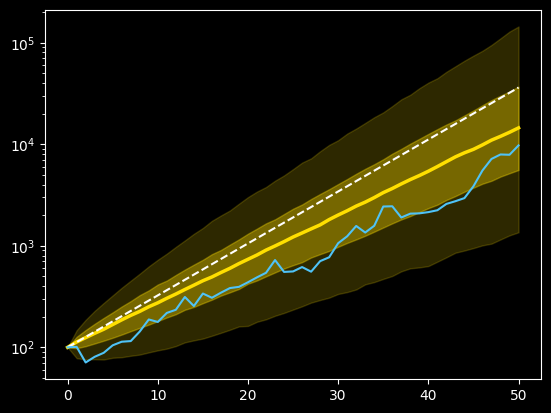

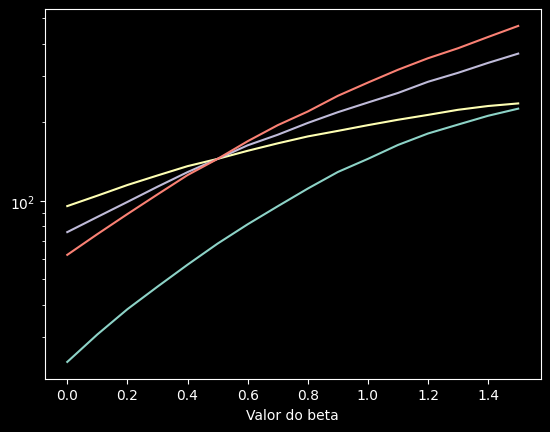

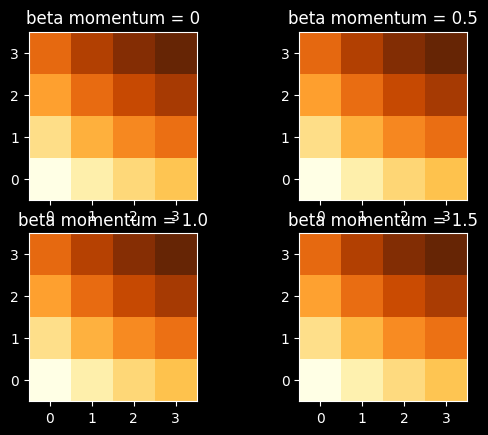

In [1]:
#Passo 1: parâmetros
import numpy as np

rng = np.random.default_rng(42)
rf = 0.03
premios = np.array([0.05, 0.02, 0.03, 0.04])
vols    = np.array([0.16, 0.10, 0.10, 0.12])
vol_propria = 0.10
anos = 50
W0 = 100

#Passo 2: os fatores
F = rng.normal(premios, vols, (anos, 4))

print(F.shape)
print(np.round(F.mean(axis=0), 3))

#Passo 3: as cinco ações
nomes = ["Mercado", "Tamanho", "Valor",
         "Momentum", "Completa"]
betas = np.array([
    [1.0, 0.0, 0.0, 0.0],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 0.0],
    [0.0, 0.0, 0.0, 1.0],
    [1.0, 0.5, 0.5, 0.5],
])
ruido = rng.normal(0, vol_propria, (anos, 5))
r_acoes = rf + F @ betas.T + ruido

#Passo 4: a riqueza em 50 anos
riqueza = W0 * np.cumprod(1 + r_acoes, axis=0)
final = riqueza[-1]

for nome, v in zip(nomes, final):
    print(f"{nome}: {v:,.0f}")

#Gráfico 1: a riqueza das cinco ações
import matplotlib.pyplot as plt
plt.style.use("dark_background")
amarelo = "#FFDF00"
cores = ["white", "#9AA0A6", "#4FC3F7",
         "#FF8A65", amarelo]

t = np.arange(anos + 1)
for i, nome in enumerate(nomes):
    caminho = np.r_[W0, riqueza[:, i]]
    plt.plot(t, caminho, color=cores[i], label=nome)
plt.yscale("log")
plt.xlabel("Anos")
plt.legend()
plt.show()

#Passo 5: a álgebra
er = rf + betas @ premios
vol = np.sqrt((betas**2) @ vols**2 + vol_propria**2)
esperado = W0 * (1 + er) ** anos

for n, e, v, w in zip(nomes, er, vol, esperado):
    print(f"{n}: E(R) = {e:.1%}  vol = {v:.1%}  "
          f"riqueza = {w:,.0f}")

#Passo 6: a mediana de 5.000 vidas
def simular(b, n=5000, seed=1):
    g = np.random.default_rng(seed)
    f = g.normal(premios, vols, (n, anos, 4))
    e = g.normal(0, vol_propria, (n, anos))
    r = rf + f @ np.asarray(b) + e
    return W0 * np.prod(np.maximum(1 + r, 0.01), axis=1)

mediana = [np.median(simular(b)) for b in betas]

#Gráfico 2: esperado, mediana e um caminho
x = np.arange(5)
plt.bar(x - 0.27, esperado / W0, 0.27, color="white")
plt.bar(x, np.array(mediana) / W0, 0.27, color=amarelo)
plt.bar(x + 0.27, final / W0, 0.27, color="gray")
plt.yscale("log")
plt.xticks(x, nomes)
plt.show()

#Passo 7: estimar os betas
X = np.column_stack([np.ones(anos), F])
y = r_acoes[:, 4] - rf
coef, *_ = np.linalg.lstsq(X, y, rcond=None)

res = y - X @ coef
var = res.var(ddof=5) * np.linalg.inv(X.T @ X)
ep = np.sqrt(np.diag(var))
print(np.round(coef, 3))
print(np.round(ep, 3))

#Passo 8: o leque da ação Completa
n = 5000
g = np.random.default_rng(1)
f = g.normal(premios, vols, (n, anos, 4))
e = g.normal(0, vol_propria, (n, anos))
r = rf + f @ betas[4] + e
c = W0 * np.cumprod(np.maximum(1 + r, 0.01), axis=1)
c = np.c_[np.full(n, W0), c]
q = np.percentile(c, [5, 25, 50, 75, 95], axis=0)

plt.fill_between(t, q[0], q[4], color=amarelo, alpha=0.18)
plt.fill_between(t, q[1], q[3], color=amarelo, alpha=0.35)
plt.plot(t, q[2], color=amarelo, lw=2.5)
plt.plot(t, W0 * (1 + er[4]) ** t, "w--")
plt.plot(t, np.r_[W0, riqueza[:, 4]], color="#4FC3F7")
plt.yscale("log")
plt.show()

#Passo 9: um beta por vez
base = np.array([1.0, 0.5, 0.5, 0.5])
grade = np.linspace(0, 1.5, 16)

for k in range(4):
    ys = []
    for v in grade:
        b = base.copy()
        b[k] = v
        ys.append(np.median(simular(b)) / W0)
    plt.plot(grade, ys)
plt.yscale("log")
plt.xlabel("Valor do beta")
plt.show()

#Passo 10: quatro dimensões
from matplotlib.colors import LogNorm
valores = [0, 0.5, 1.0, 1.5]
fig, eixos = plt.subplots(2, 2)

for ax, m in zip(eixos.flat, valores):
    z = np.array([[np.median(simular([1.0, s, v, m])) / W0
                   for s in valores] for v in valores])
    ax.imshow(z, origin="lower", cmap="YlOrBr",
              norm=LogNorm())
    ax.set_title(f"beta momentum = {m}")
plt.show()